1. **lagrangian analysis:** three subplots containing the 50-m advection, in (a) back track, (b) east releasing and (c) north releasing. The figure must contain:
	1. isobaths (200, 1000, 2000, 4000)
	2. coordinates in the left and bottom axis
	3. the releasing point in red
	4. name of main places (Guanabara, Cabo Frio, Cabo São Tomé, Tubarão Bight)

In [1]:
import xarray as xr
import numpy as np
import math
from datetime import timedelta,datetime
from operator import attrgetter
import matplotlib.pyplot as plt
import cartopy.feature as cfeature
import cartopy.crs as ccrs

import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

import sys
sys.path.insert(0, '/home/danilo/phd/thesis/chapter_colab/scripts/')
from load_profiles import load_vertical_profiles
from utils import subplots_structure

In [2]:
dict_casts = load_vertical_profiles()

# plotting with my functions
zoomed_extent= [-50, -37, -30, -22] #[-45, -39, -27, -22]

Processing cast1...
Processing cast2...
Processing cast3.2...
Processing cast6...
Processing cast7...


In [3]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [4]:
# glorys_current_fields = xr.open_dataset('/home/danilo/phd/thesis/chapter_colab/data/sanagu2022/glorys_current_*.nc')

experiments = {
    "smax_from_backpropag_cmems": {
                'outfile': xr.open_zarr('/home/danilo/phd/thesis/chapter_colab/scripts/lagrangean/smax_from_backpropag_cmems.zarr'),
                'center_launch': [-42.768, -23.64],
                },
    "smax_from_east_cmems": {
                'outfile': xr.open_zarr('/home/danilo/phd/thesis/chapter_colab/scripts/lagrangean/smax_from_east_cmems.zarr'),
                'center_launch': [-39, -26.5],
                },
    "smax_from_north_cmems": {
                'outfile': xr.open_zarr('/home/danilo/phd/thesis/chapter_colab/scripts/lagrangean/smax_from_north_cmems.zarr'),
                'center_launch': [-40, -22],
                },
}
experiments.keys()

dict_keys(['smax_from_backpropag_cmems', 'smax_from_east_cmems', 'smax_from_north_cmems'])

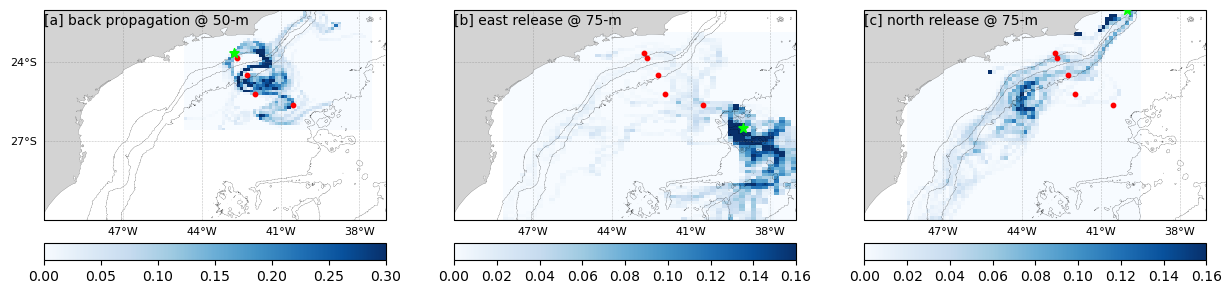

In [7]:
fig,axes = subplots_structure(3, 1, (15,10), 3)
titles = ['[a] back propagation @ 50-m', '[b] east release @ 75-m' ,'[c] north release @ 75-m']
maxvalues = [0.3, 0.16, 0.16]

cont = 0

for key,ax in zip(experiments.keys(), axes):
    p = experiments[key]['outfile']
    lons = p.lon.values[~np.isnan(p.lon.values)].ravel()
    lats = p.lat.values[~np.isnan(p.lat.values)].ravel()
    _ = ax.hist2d(lons, lats, bins=60, cmap='Blues', density=True, vmin=0, vmax=maxvalues[cont])
    cb = plt.colorbar(_[-1], location='bottom', pad=.03)
    
    ax.set_extent(zoomed_extent, crs=ccrs.PlateCarree())

    states_provinces = cfeature.NaturalEarthFeature(
            category='physical',name='coastline',scale='10m',
            facecolor='lightgray')
    ax.add_feature(states_provinces, edgecolor='black',linewidth=.1)

    ### CONFIGURING MERIDIANS AND PARALLELS
    gl = ax.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,linewidth=.4,
                    color='gray', alpha=0.5, linestyle='--',
                    xlocs=list(np.arange(zoomed_extent[0], zoomed_extent[1], 3)),
                    ylocs=list(np.arange(zoomed_extent[2], zoomed_extent[3], 3)),)
    
    if cont == 0:
        gl.xlabels_top = False
        gl.ylabels_right = False
    else:
        gl.xlabels_top = False
        gl.ylabels_right = False
        gl.ylabels_left = False

    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.ylabel_style = {'color': 'black', 'fontsize': '8'}
    gl.xlabel_style = {'color': 'black', 'fontsize': '8'}
    
    # plotting selected profiles locations
    for cast,values in dict_casts.items():
        prof = values['prof']
        str_time = values['time'].strftime("%m/%d")
        xlon = values['xlon']
        ylat = values['ylat']

        ax.scatter(xlon, ylat, c='r', s=10)

    ax.scatter(experiments[key]['center_launch'][0], experiments[key]['center_launch'][1], marker='*', c='lime', s=50, zorder=10)
    ax.set_title(titles[cont], loc='left', fontsize=10, y=0.89)
    bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -2000, -4000], 
                             colors=('k'), linewidths=(0.2), linestyles=('--'))
    
    cont += 1

fig.patch.set_alpha(1.0)
# plt.savefig('../figures/manuscript/00_manuscript_lagrangian_analysis.png', bbox_inches="tight", dpi=300)

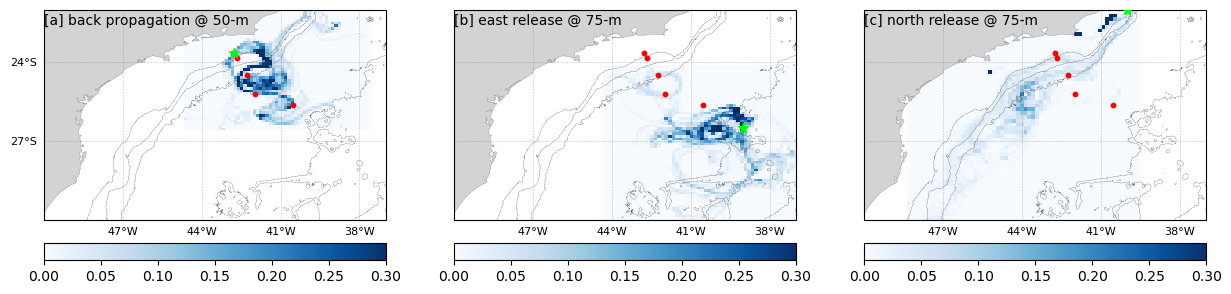